In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

In [3]:
data = {
    'Hours' : [1, 2,3, 4, 5,6,7,8,9,10],
    'Performance' : [3 , 8, 15, 25, 38, 55, 75 ,100 , 130, 165]
}
df = pd.DataFrame(data)
print(df)

   Hours  Performance
0      1            3
1      2            8
2      3           15
3      4           25
4      5           38
5      6           55
6      7           75
7      8          100
8      9          130
9     10          165


In [13]:
X = df[['Hours']]
y = df['Performance']

In [14]:
X

,Hours
0,1
1,2
2,3
3,4
4,5
5,6
6,7
7,8
8,9
9,10


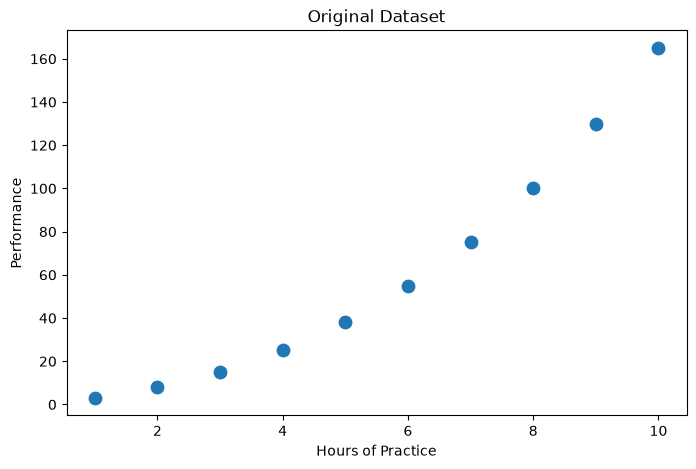

In [9]:
plt.figure(figsize=(8 ,5))
plt.scatter(X, y, colorizer='blue', s=80)
plt.xlabel('Hours of Practice')
plt.ylabel('Performance')
plt.title('Original Dataset')

plt.show()

In [39]:
poly = PolynomialFeatures(degree=4) #8->Overfit
x_poly = poly.fit_transform(X)
print(x_poly)

[[1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00]
 [1.000e+00 2.000e+00 4.000e+00 8.000e+00 1.600e+01]
 [1.000e+00 3.000e+00 9.000e+00 2.700e+01 8.100e+01]
 [1.000e+00 4.000e+00 1.600e+01 6.400e+01 2.560e+02]
 [1.000e+00 5.000e+00 2.500e+01 1.250e+02 6.250e+02]
 [1.000e+00 6.000e+00 3.600e+01 2.160e+02 1.296e+03]
 [1.000e+00 7.000e+00 4.900e+01 3.430e+02 2.401e+03]
 [1.000e+00 8.000e+00 6.400e+01 5.120e+02 4.096e+03]
 [1.000e+00 9.000e+00 8.100e+01 7.290e+02 6.561e+03]
 [1.000e+00 1.000e+01 1.000e+02 1.000e+03 1.000e+04]]


In [40]:
model = LinearRegression()

In [41]:
model.fit(x_poly, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[0. ,1.87,0.87,0.05,0. ]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.25
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[10228.05, 126.69, 4.53, 0.25, 0. ]"


In [42]:
new_data = pd.DataFrame({
    'Hours' : [11]
})
new_data_poly = poly.transform(new_data)
prediction = model.predict(new_data_poly)
print("Predicted Performance : " , prediction[0])

Predicted Performance :  206.08333333333326


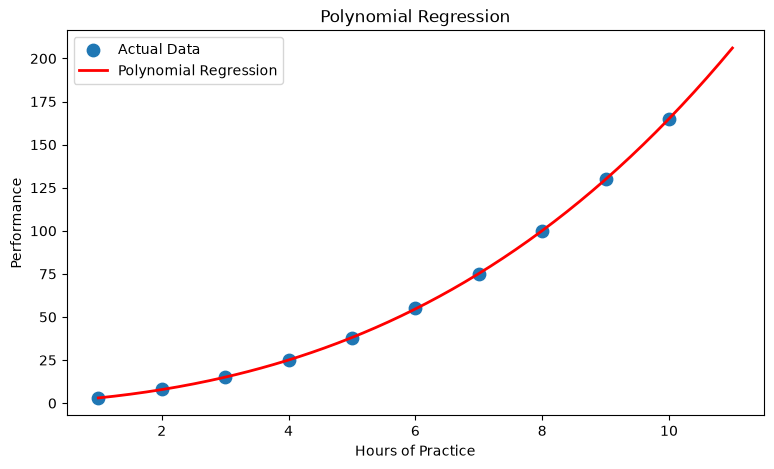

In [43]:
X_curve = pd.DataFrame({
    'Hours' : np.linspace(1, 11, 200)
})
X_curve_poly = poly.transform(X_curve)
y_curve = model.predict(X_curve_poly)
plt.figure(figsize=(9 , 5))
plt.scatter(
    X,
    y,
    colorizer='blue',
    label = 'Actual Data',
    s=80
)
plt.plot(
    X_curve,
    y_curve,
    color = 'red',
    label = 'Polynomial Regression',
    linewidth = 2
)

plt.xlabel('Hours of Practice')
plt.ylabel('Performance')
plt.title('Polynomial Regression')

plt.legend()
plt.show()